# Reproducibility Study of Graph Convolutional Networks for Semi-Supervised Learning

**Course:** CS 679  
**Paper:** Kipf, T. N., & Welling, M. (2017). *Semi-Supervised Classification with Graph Convolutional Networks*.

## Objective

This notebook reproduces the Cora semi-supervised node classification result from the original GCN paper and adds one small extension: a label sparsity study comparing a graph-aware GCN with a feature-only MLP baseline.

## 1. Environment / setup

The notebook is meant to run top to bottom. The reusable implementation lives in `src/`, while the notebook focuses on the experimental workflow and the saved outputs.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_cora_dataset, sample_label_sparsity_split, with_splits
from src.eval import format_mean_std, summarize_results
from src.export import create_export_manager
from src.plots import plot_label_sparsity, plot_model_comparison, plot_training_curves, plot_tsne
from src.train import TrainConfig, run_experiment, run_repeated_experiments
from src.utils import get_device

plt.style.use("seaborn-v0_8-whitegrid")
device = get_device(prefer_gpu=False)
device

device(type='cpu')

### Export pipeline

Each notebook execution creates a new folder under `results/runs/` and saves the figures, tables, logs, configuration, and summary for that run. Report-ready copies from the most recent successful execution are also mirrored into `results/aggregated/`.

In [2]:
RESULTS_ROOT = PROJECT_ROOT / "results"
exporter = create_export_manager(RESULTS_ROOT)

RUN_ID = exporter.run_id
RUN_DIR = exporter.run_dir
RUN_FIGURES_DIR = exporter.figures_dir
RUN_TABLES_DIR = exporter.tables_dir
RUN_LOGS_DIR = exporter.logs_dir
AGGREGATED_DIR = exporter.aggregated_dir

print(f"Run id: {RUN_ID}")
print(f"Run folder: {RUN_DIR}")
print(f"Figures folder: {RUN_FIGURES_DIR}")
print(f"Tables folder: {RUN_TABLES_DIR}")
print(f"Aggregated folder: {AGGREGATED_DIR}")

Run id: run_001
Run folder: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001
Figures folder: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001/figures
Tables folder: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001/tables
Aggregated folder: /Users/akshaysanthosh/Desktop/GNN/results/aggregated


## 2. Dataset overview

We use the Cora citation network in the same public Planetoid split used by the original GCN code release: 140 training nodes, 500 validation nodes, and 1000 test nodes. Features are row-normalized, the graph is symmetrized, and the adjacency matrix is renormalized with self-loops using the standard GCN preprocessing.

In [3]:
data = load_cora_dataset(PROJECT_ROOT / "data")

dataset_overview = pd.DataFrame(
    {
        "Statistic": [
            "Number of nodes",
            "Number of features",
            "Number of classes",
            "Training nodes",
            "Validation nodes",
            "Test nodes",
        ],
        "Value": [
            data.num_nodes,
            data.num_features,
            data.num_classes,
            len(data.idx_train),
            len(data.idx_val),
            len(data.idx_test),
        ],
    }
)

exporter.save_table(dataset_overview, "dataset_overview", aggregate=True)
display(dataset_overview)

,Statistic,Value
0,Number of nodes,2708
1,Number of features,1433
2,Number of classes,7
3,Training nodes,140
4,Validation nodes,500
5,Test nodes,1000


## 3. Model definitions

We compare a graph-aware GCN against a feature-only baseline under the same Cora semi-supervised setting.

- **MLP baseline:** a feature-only 2-layer network that ignores graph structure.
- **GCN:** a 2-layer graph convolutional network with the normalized adjacency matrix applied explicitly in each layer.

Both models use the same hidden size, ReLU activation, dropout, and Adam so that the main difference is whether graph structure is used.

## 4. Training procedure

The training configuration below is intentionally simple and close to the original GCN setup.

### Paper-faithful reproduction settings

- dataset: Cora citation network
- split: public / Planetoid split with 140 training nodes, 500 validation nodes, and 1000 test nodes
- models: 2-layer GCN and a feature-only 2-layer MLP baseline with the same hidden size
- graph preprocessing: renormalized adjacency with self-loops, using $\hat{A} = D^{-1/2}(A + I)D^{-1/2}$
- hidden activation: ReLU
- hidden dimension = 16
- dropout = 0.5
- optimizer = Adam
- learning rate = 0.01
- weight decay = 5e-4 applied to the first layer weights
- early stopping follows the original public GCN implementation: stop when the current validation loss is worse than the mean of the previous 10 validation losses
- cross-entropy computed only on labeled training nodes

The code cell below instantiates the shared training configuration, the seed list used for repeated evaluation, and the label budgets used in the extension experiment.

In [4]:
config = TrainConfig(
    hidden_dim=16,
    dropout=0.5,
    learning_rate=0.01,
    weight_decay=5e-4,
    max_epochs=200,
    patience=10,
)

seeds = [0, 1, 2, 3, 4]
label_budgets = [1, 3, 5, 10, 20]

config_payload = {
    "run_id": RUN_ID,
    "timestamp": exporter.timestamp,
    "dataset": "Cora",
    "models": ["MLP", "GCN"],
    "hidden_dim": config.hidden_dim,
    "dropout": config.dropout,
    "learning_rate": config.learning_rate,
    "weight_decay": config.weight_decay,
    "max_epochs": config.max_epochs,
    "early_stopping_patience": config.patience,
    "seed_list": seeds,
    "label_sparsity_values": label_budgets,
}

CONFIG_PATH = exporter.write_config(config_payload)
config

TrainConfig(hidden_dim=16, dropout=0.5, learning_rate=0.01, weight_decay=0.0005, max_epochs=200, patience=10)

## 5. Main reproduction results

We first run the main reproduction experiment on the standard Cora split and summarize performance across multiple random seeds.

In [5]:
main_frames = []
main_artifacts = {}

for model_name in ["mlp", "gcn"]:
    frame, artifacts = run_repeated_experiments(
        model_name=model_name,
        data=data,
        config=config,
        seeds=seeds,
        device=device,
    )
    main_frames.append(frame)
    main_artifacts[model_name.upper()] = artifacts

main_results = pd.concat(main_frames, ignore_index=True)
model_order = ["MLP", "GCN"]
main_results["model"] = pd.Categorical(main_results["model"], categories=model_order, ordered=True)
main_results = main_results.sort_values(["model", "seed"]).reset_index(drop=True)

main_summary = summarize_results(main_results, ["test_accuracy", "test_macro_f1", "stop_epoch"])
main_summary["model"] = pd.Categorical(main_summary["model"], categories=model_order, ordered=True)
main_summary = main_summary.sort_values("model").reset_index(drop=True)

comparison_table = pd.DataFrame(
    {
        "Model": main_summary["model"],
        "Accuracy (mean ± std)": main_summary.apply(
            lambda row: format_mean_std(row["test_accuracy_mean"], row["test_accuracy_std"]),
            axis=1,
        ),
        "Macro-F1 (mean ± std)": main_summary.apply(
            lambda row: format_mean_std(row["test_macro_f1_mean"], row["test_macro_f1_std"]),
            axis=1,
        ),
        "Stop epoch (mean ± std)": main_summary.apply(
            lambda row: format_mean_std(row["stop_epoch_mean"], row["stop_epoch_std"], decimals=1),
            axis=1,
        ),
    }
)

final_summary_table = comparison_table[["Model", "Accuracy (mean ± std)", "Macro-F1 (mean ± std)"]].copy()
multi_seed_results = main_results[["model", "seed", "test_accuracy", "test_macro_f1", "stop_epoch"]].copy()
multi_seed_results[["test_accuracy", "test_macro_f1"]] = multi_seed_results[["test_accuracy", "test_macro_f1"]].round(4)

MAIN_RESULTS_TABLE_PATHS = exporter.save_table(final_summary_table, "main_results", aggregate=True)
MULTI_SEED_TABLE_PATHS = exporter.save_table(multi_seed_results, "multi_seed_results", aggregate=True)
MAIN_RESULTS_SUMMARY_PATHS = exporter.save_table(main_summary, "main_results_summary", aggregate=True)
MAIN_RESULTS_LOG_PATHS = exporter.save_log_dataframe(main_results, "main_results_by_seed", aggregate=True)

representative_histories = {}
main_training_histories = {}
for model_name in ["MLP", "GCN"]:
    history = main_artifacts[model_name][0]["history"].copy()
    representative_histories[model_name] = history
    main_training_histories[model_name] = {
        str(artifact["seed"]): artifact["history"].to_dict(orient="records")
        for artifact in main_artifacts[model_name]
    }
    exporter.save_log_dataframe(history, f"{model_name.lower()}_training_history_seed_{seeds[0]}", aggregate=True)
exporter.save_log_json(main_training_histories, "main_training_histories.json", aggregate=True)

display(comparison_table)

,Model,Accuracy (mean ± std),Macro-F1 (mean ± std),Stop epoch (mean ± std)
0,MLP,0.5540 ± 0.0147,0.5440 ± 0.0131,106.2 ± 8.9
1,GCN,0.8036 ± 0.0094,0.7934 ± 0.0093,146.4 ± 38.1


## 6. Multi-seed evaluation

The next table shows the per-seed results used to compute the aggregate summary, so the variance across runs is visible.

,model,seed,test_accuracy,test_macro_f1,stop_epoch
0,MLP,0,0.547,0.5407,112
1,MLP,1,0.578,0.5651,106
2,MLP,2,0.543,0.5352,109
3,MLP,3,0.544,0.5320,91
4,MLP,4,0.558,0.5472,113
5,GCN,0,0.794,0.7860,129
6,GCN,1,0.793,0.7819,99
7,GCN,2,0.810,0.7999,135
8,GCN,3,0.813,0.8039,195
9,GCN,4,0.808,0.7951,174


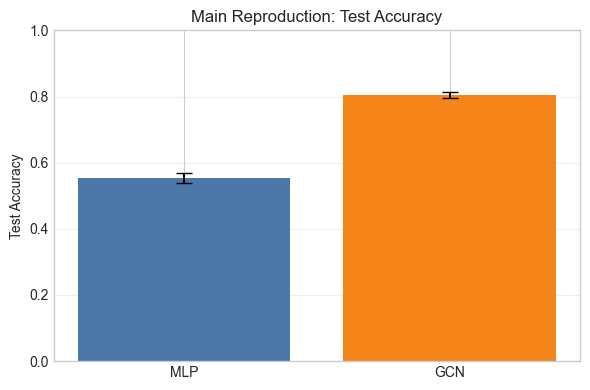

In [6]:
display(multi_seed_results)

main_comparison_figure = plot_model_comparison(
    main_summary,
    metric="test_accuracy",
    title="Main Reproduction: Test Accuracy",
)
MAIN_COMPARISON_FIGURE_PATH = exporter.save_figure(main_comparison_figure, "main_results_comparison.png", aggregate=True)
plt.show()

## 7. Training curves

To visualize optimization behavior, we plot representative training and validation curves from the first seed of each model.

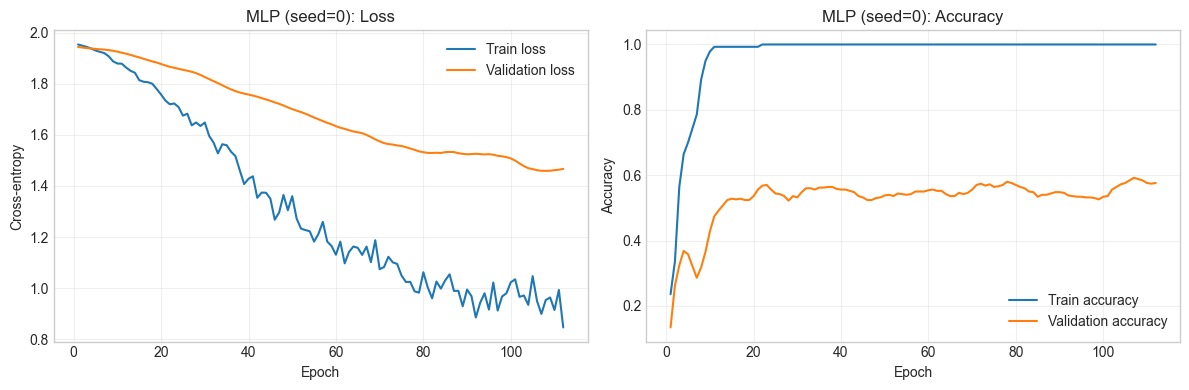

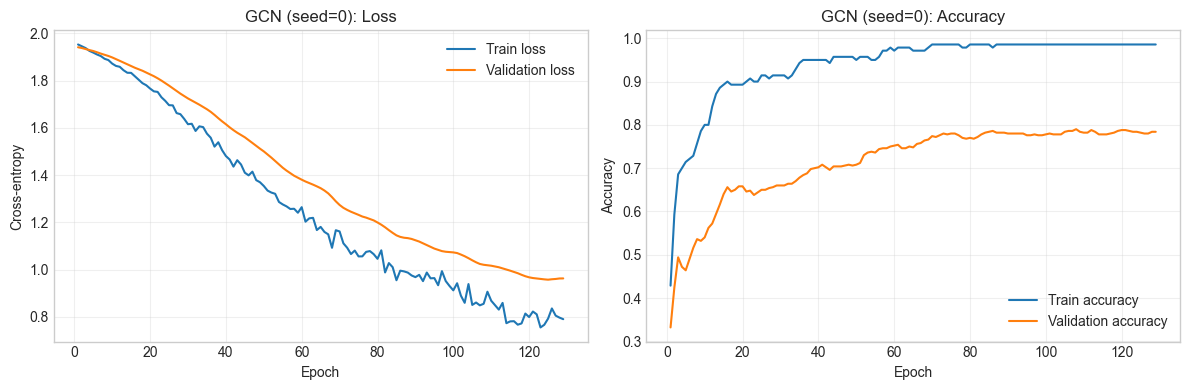

In [7]:
training_curve_paths = {}

for model_name in ["MLP", "GCN"]:
    training_curve_figure = plot_training_curves(
        representative_histories[model_name],
        title=f"{model_name} (seed={seeds[0]})",
    )
    training_curve_paths[model_name] = exporter.save_figure(
        training_curve_figure,
        f"{model_name.lower()}_training_curves.png",
        aggregate=True,
    )
    plt.show()

## 8. t-SNE visualization

We visualize the hidden representations learned by each model using t-SNE. Clearer class separation in the GCN embedding would be qualitatively consistent with the paper's claim that graph structure improves semi-supervised classification.

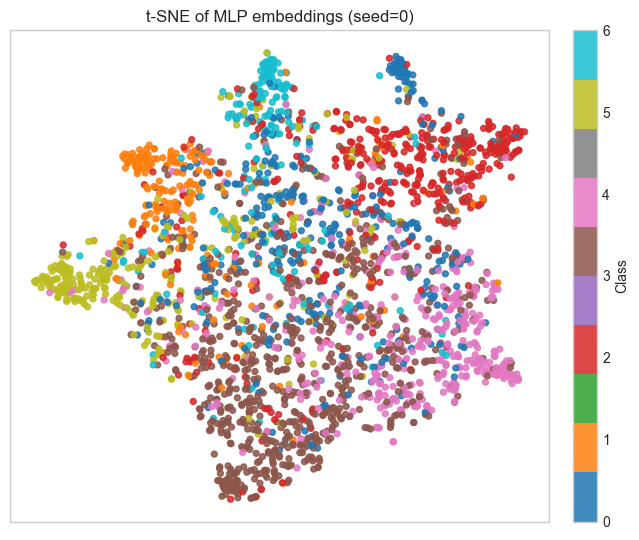

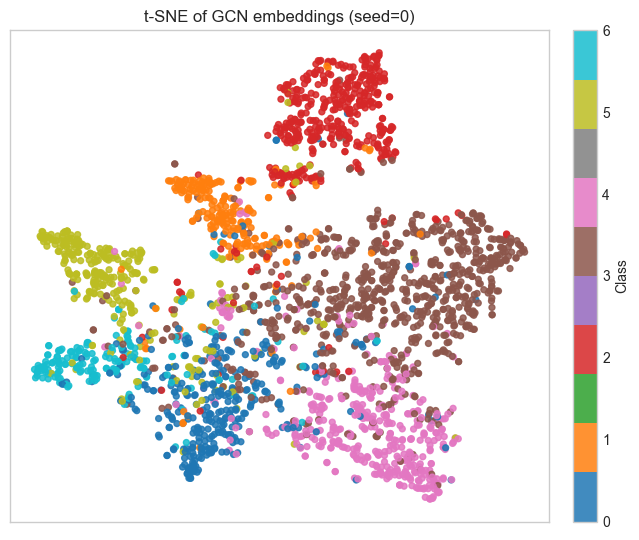

In [8]:
tsne_paths = {}

for model_name in ["MLP", "GCN"]:
    embeddings = main_artifacts[model_name][0]["embeddings"].numpy()
    tsne_figure = plot_tsne(
        embeddings=embeddings,
        labels=data.labels.numpy(),
        title=f"t-SNE of {model_name} embeddings (seed={seeds[0]})",
        seed=seeds[0],
    )
    tsne_paths[model_name] = exporter.save_figure(
        tsne_figure,
        f"tsne_{model_name.lower()}.png",
        aggregate=True,
    )
    plt.show()

## 9. Label sparsity experiment

As a small extension, we reduce the number of labeled training nodes per class and compare how the MLP and GCN degrade under limited supervision. This is not part of the original paper; it reuses the original test split while resampling class-balanced training nodes and a fresh validation set from the remaining non-test nodes.

,labels_per_class,model,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std
0,1,MLP,0.1944,0.0660,0.1365,0.0702
1,1,GCN,0.2458,0.1056,0.2126,0.1243
2,3,MLP,0.3344,0.0877,0.3042,0.0761
3,3,GCN,0.5500,0.0531,0.5490,0.0465
4,5,MLP,0.3812,0.0445,0.3637,0.0425
5,5,GCN,0.6246,0.0243,0.6237,0.0225
6,10,MLP,0.4586,0.0311,0.4482,0.0251
7,10,GCN,0.7234,0.0325,0.7179,0.0276
8,20,MLP,0.5468,0.0390,0.5354,0.0320
9,20,GCN,0.7838,0.0135,0.7716,0.0133


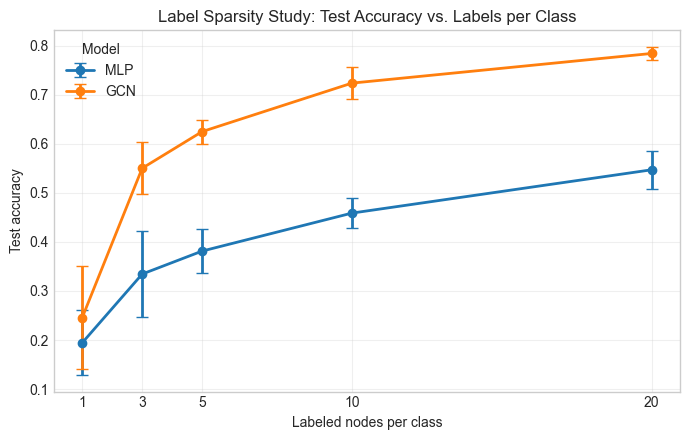

In [9]:
sparsity_rows = []

for labels_per_class in label_budgets:
    for seed in seeds:
        idx_train, idx_val, idx_test = sample_label_sparsity_split(
            labels=data.labels,
            idx_test=data.idx_test,
            labels_per_class=labels_per_class,
            seed=seed,
        )
        sparse_data = with_splits(data, idx_train=idx_train, idx_val=idx_val, idx_test=idx_test)

        for model_name in ["mlp", "gcn"]:
            result = run_experiment(
                model_name=model_name,
                data=sparse_data,
                config=config,
                seed=seed,
                device=device,
            )
            sparsity_rows.append(
                {
                    "labels_per_class": labels_per_class,
                    "model": result["model"],
                    "seed": seed,
                    "test_accuracy": result["test_accuracy"],
                    "test_macro_f1": result["test_macro_f1"],
                    "stop_epoch": result["stop_epoch"],
                }
            )

sparsity_results = pd.DataFrame(sparsity_rows)
sparsity_results["model"] = pd.Categorical(sparsity_results["model"], categories=model_order, ordered=True)
sparsity_results = sparsity_results.sort_values(["labels_per_class", "model", "seed"]).reset_index(drop=True)

label_sparsity_summary = (
    sparsity_results.groupby(["labels_per_class", "model"])
    .agg(
        test_accuracy_mean=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        test_macro_f1_mean=("test_macro_f1", "mean"),
        test_macro_f1_std=("test_macro_f1", "std"),
    )
    .reset_index()
)
label_sparsity_summary["model"] = pd.Categorical(label_sparsity_summary["model"], categories=model_order, ordered=True)
label_sparsity_summary = label_sparsity_summary.sort_values(["labels_per_class", "model"]).reset_index(drop=True)

sparsity_display = label_sparsity_summary.copy()
numeric_columns = [column for column in sparsity_display.columns if column not in ["labels_per_class", "model"]]
sparsity_display[numeric_columns] = sparsity_display[numeric_columns].round(4)

LABEL_SPARSITY_TABLE_PATHS = exporter.save_table(sparsity_display, "label_sparsity_results", aggregate=True)
LABEL_SPARSITY_LOG_PATHS = exporter.save_log_dataframe(sparsity_results, "label_sparsity_results_by_seed", aggregate=True)
exporter.save_table(label_sparsity_summary, "label_sparsity_summary", aggregate=True)

display(sparsity_display)

label_sparsity_figure = plot_label_sparsity(
    sparsity_results,
    metric="test_accuracy",
)
LABEL_SPARSITY_FIGURE_PATH = exporter.save_figure(
    label_sparsity_figure,
    "label_sparsity_accuracy.png",
    aggregate=True,
)
plt.show()

Key observations from the label sparsity study:

- GCN outperforms the MLP baseline at every label budget tested.
- The performance gap is especially visible in low-label regimes, which is consistent with the idea that graph structure is most useful when labeled supervision is scarce.
- As the number of labels per class increases, both models improve, but the GCN remains clearly stronger.

## 10. Final summary table

The table below collects the main reproduction result in the compact format used in the report.

In [10]:
display(final_summary_table)

,Model,Accuracy (mean ± std),Macro-F1 (mean ± std)
0,MLP,0.5540 ± 0.0147,0.5440 ± 0.0131
1,GCN,0.8036 ± 0.0094,0.7934 ± 0.0093


The main claim is reproduced: the GCN outperforms the feature-only MLP baseline by a large margin on both accuracy and macro-F1, and the outcome is qualitatively consistent with the original paper.

## 11. Discussion and reproducibility notes

### Discussion

1. **Did we reproduce the main claim?** Yes. Across multiple random seeds, the GCN consistently outperformed the feature-only MLP baseline on both test accuracy and macro-F1.

2. **How close were the results to the original paper?** The reproduced GCN accuracy is in the same qualitative range as the original result and supports the same conclusion, even if an exact numerical match is not expected.

3. **What might explain differences from the paper?** Small differences can come from implementation details, modern library behavior, CPU versus GPU execution, random initialization, and the choice to report repeated-seed summaries instead of a single headline run.

4. **What did the label sparsity extension show?** The GCN remained stronger than the MLP across all tested label budgets, with the advantage becoming especially noticeable when only a few labeled nodes per class were available.

### Deviations from the original paper

- This course project reproduces only the Cora experiment rather than the full multi-dataset scope of the paper.
- The implementation is a clean PyTorch reimplementation rather than the original TensorFlow codebase.
- Repeated-seed mean ± standard deviation analysis extends the base single-run reproduction.
- The label sparsity study is an additional extension beyond the original paper.
- Dense normalized adjacency is used for clarity because Cora is small enough for this to remain practical in a course project.

In [11]:
main_summary_metrics = main_summary.set_index("model")
gcn_accuracy = float(main_summary_metrics.loc["GCN", "test_accuracy_mean"])
mlp_accuracy = float(main_summary_metrics.loc["MLP", "test_accuracy_mean"])
gcn_macro_f1 = float(main_summary_metrics.loc["GCN", "test_macro_f1_mean"])
mlp_macro_f1 = float(main_summary_metrics.loc["MLP", "test_macro_f1_mean"])
gcn_outperformed_mlp = bool(gcn_accuracy > mlp_accuracy and gcn_macro_f1 > mlp_macro_f1)

accuracy_gaps = []
for labels_per_class in label_budgets:
    subset = label_sparsity_summary[label_sparsity_summary["labels_per_class"] == labels_per_class].set_index("model")
    gap = float(subset.loc["GCN", "test_accuracy_mean"] - subset.loc["MLP", "test_accuracy_mean"])
    accuracy_gaps.append({"labels_per_class": labels_per_class, "accuracy_gap": round(gap, 4)})

largest_gap_entry = max(accuracy_gaps, key=lambda item: item["accuracy_gap"])
label_sparsity_conclusions = [
    "GCN outperformed MLP at every tested label budget.",
    f"The largest average accuracy gap was {largest_gap_entry['accuracy_gap']:.4f} at {largest_gap_entry['labels_per_class']} labels per class.",
    "Both models improved as more labels were provided, but the GCN remained clearly stronger.",
]

run_summary = {
    "run_id": RUN_ID,
    "timestamp": exporter.timestamp,
    "dataset": "Cora",
    "number_of_seeds": len(seeds),
    "seed_list": seeds,
    "main_results": {
        "MLP": {
            "accuracy_mean": round(mlp_accuracy, 4),
            "accuracy_std": round(float(main_summary_metrics.loc["MLP", "test_accuracy_std"]), 4),
            "macro_f1_mean": round(mlp_macro_f1, 4),
            "macro_f1_std": round(float(main_summary_metrics.loc["MLP", "test_macro_f1_std"]), 4),
        },
        "GCN": {
            "accuracy_mean": round(gcn_accuracy, 4),
            "accuracy_std": round(float(main_summary_metrics.loc["GCN", "test_accuracy_std"]), 4),
            "macro_f1_mean": round(gcn_macro_f1, 4),
            "macro_f1_std": round(float(main_summary_metrics.loc["GCN", "test_macro_f1_std"]), 4),
        },
    },
    "gcn_outperformed_mlp": gcn_outperformed_mlp,
    "label_sparsity_conclusions": label_sparsity_conclusions,
    "paths": {
        "run_dir": str(RUN_DIR),
        "figures_dir": str(RUN_FIGURES_DIR),
        "tables_dir": str(RUN_TABLES_DIR),
        "logs_dir": str(RUN_LOGS_DIR),
        "aggregated_dir": str(AGGREGATED_DIR),
        "main_results_table": str(MAIN_RESULTS_TABLE_PATHS["csv"]),
        "multi_seed_results_table": str(MULTI_SEED_TABLE_PATHS["csv"]),
        "label_sparsity_results_table": str(LABEL_SPARSITY_TABLE_PATHS["csv"]),
        "main_results_figure": str(MAIN_COMPARISON_FIGURE_PATH),
        "label_sparsity_figure": str(LABEL_SPARSITY_FIGURE_PATH),
    },
}

RUN_SUMMARY_PATH = exporter.write_run_summary(run_summary)
MANIFEST_PATH = exporter.write_manifest()

print(f"Run id: {RUN_ID}")
print(f"Run folder: {RUN_DIR}")
print(f"Config file: {CONFIG_PATH}")
print(f"Run summary: {RUN_SUMMARY_PATH}")
print(f"Manifest: {MANIFEST_PATH}")
print("Saved figures:")
for item in exporter.manifest["figures"]:
    print(f"- {item['path']}")
print("Saved tables:")
for item in exporter.manifest["tables"]:
    print(f"- {item['path']}")
print("Saved logs:")
for item in exporter.manifest["logs"]:
    print(f"- {item['path']}")

Run id: run_001
Run folder: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001
Config file: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001/config.json
Run summary: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001/run_summary.json
Manifest: /Users/akshaysanthosh/Desktop/GNN/results/runs/run_001/manifest.json
Saved figures:
- runs/run_001/figures/main_results_comparison.png
- runs/run_001/figures/mlp_training_curves.png
- runs/run_001/figures/gcn_training_curves.png
- runs/run_001/figures/tsne_mlp.png
- runs/run_001/figures/tsne_gcn.png
- runs/run_001/figures/label_sparsity_accuracy.png
Saved tables:
- runs/run_001/tables/dataset_overview.csv
- runs/run_001/tables/dataset_overview.json
- runs/run_001/tables/main_results.csv
- runs/run_001/tables/main_results.json
- runs/run_001/tables/multi_seed_results.csv
- runs/run_001/tables/multi_seed_results.json
- runs/run_001/tables/main_results_summary.csv
- runs/run_001/tables/main_results_summary.json
- runs/run_001/tables/la